# Goal: check the timing, time interpolation and spatial remapping of ERA5 forcing.

In [1]:
import xarray as xr
import xesmf
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

We use the 2011-10-01 forcing file for ERA5

In [2]:
era5_original = "/work/noaa/marine/rdussin/datasets/ERA5/forcing_UFS/"
era5_ds = xr.open_mfdataset(f"{era5_original}/era5_forcing_y2011m10d0[1-2].nc").sel(time=slice("2011-10-01", "2011-10-02T00:00:00"))

The simplest field to use to check timing is the solar radiation:

In [3]:
era5_ds

<xarray.Dataset> Size: 2GB
Dimensions:       (time: 25, lat: 721, lon: 1440)
Coordinates:
  * time          (time) datetime64[ns] 200B 2011-10-01 ... 2011-10-02
  * lat           (lat) float32 3kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Data variables: (12/21)
    DLWRF         (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    DSWRF         (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    vbdsf_ave     (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    vddsf_ave     (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    nbdsf_ave     (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    nddsf_ave     (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    ...            ...
    tmp_hyblev1   (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    ugrd_hyblev1  (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    vgrd_hyblev1  (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    pres_hyblev1  (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    hgt_hyblev1   (time, lat, lon) float32 104MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    slmsksfc      (time, lat, lon) float64 208MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>

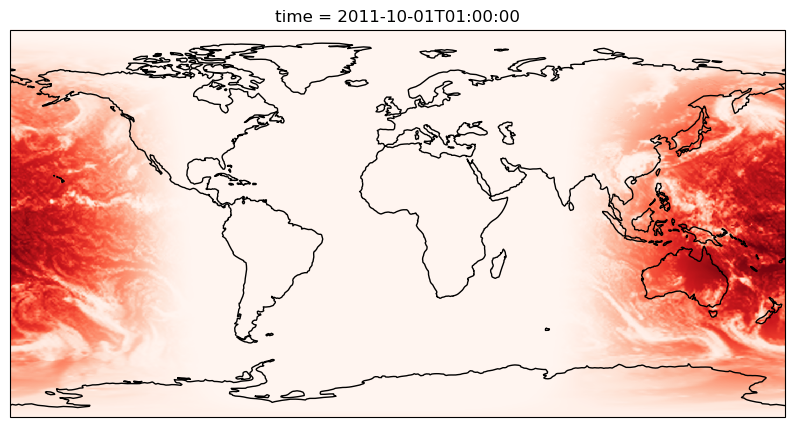

In [4]:
# ERA5 SW at start + 1:00h is index 1
plt.figure(figsize=[10,7])
ax = plt.axes(projection=ccrs.PlateCarree())
era5_ds["vddsf_ave"].isel(time=1).plot(ax=ax, cmap="Reds", transform=ccrs.PlateCarree(), add_colorbar=False)
ax.coastlines(color="k")

In [5]:
rundir = "/work/noaa/stmp/rdussin/EXPDIR/orion/p008"
datm_hist = xr.open_mfdataset(f"{rundir}/datm.gfs.cpl.hi.atm.2011-10-0[1-2]-*.nc")

In [6]:
datm_hist

<xarray.Dataset> Size: 5GB
Dimensions:              (time: 24, ntb: 2, atmImp_ny: 721, atmImp_nx: 1440,
                          Med_frac_atm_ny: 721, Med_frac_atm_nx: 1440)
Coordinates:
  * time                 (time) datetime64[ns] 192B 2011-10-01T01:00:00 ... 2...
Dimensions without coordinates: ntb, atmImp_ny, atmImp_nx, Med_frac_atm_ny,
                                Med_frac_atm_nx
Data variables: (12/28)
    time_bnds            (time, ntb) float64 384B dask.array<chunksize=(1, 2), meta=np.ndarray>
    atmImp_Faxa_lwdn     (time, atmImp_ny, atmImp_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    atmImp_Faxa_rain     (time, atmImp_ny, atmImp_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    atmImp_Faxa_snow     (time, atmImp_ny, atmImp_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    atmImp_Faxa_swndf    (time, atmImp_ny, atmImp_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    atmImp_Faxa_swndr    (time, atmImp_ny, atmImp_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    ...                   ...
    Med_frac_atm_ifrac   (time, Med_frac_atm_ny, Med_frac_atm_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    Med_frac_atm_lfrac   (time, Med_frac_atm_ny, Med_frac_atm_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    Med_frac_atm_lfrin   (time, Med_frac_atm_ny, Med_frac_atm_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    Med_frac_atm_ofrac   (time, Med_frac_atm_ny, Med_frac_atm_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    Med_frac_atm_lon     (time, Med_frac_atm_ny, Med_frac_atm_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    Med_frac_atm_lat     (time, Med_frac_atm_ny, Med_frac_atm_nx) float64 199MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes:
    file_version:   cmeps0
    model_doi_url:  unset

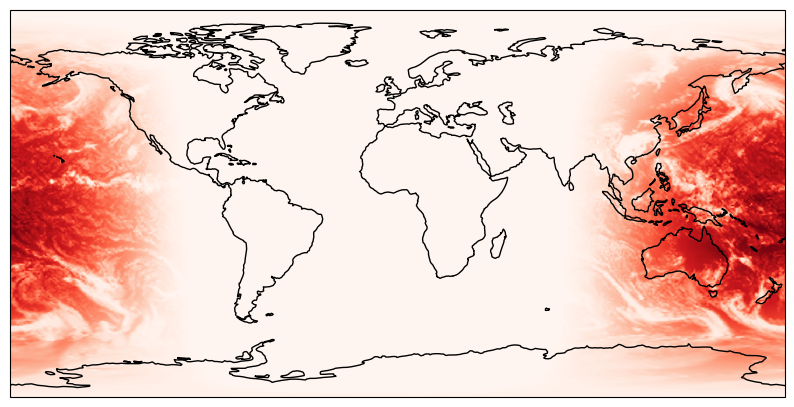

In [7]:
# index 0 is 1:00AM 
plt.figure(figsize=[10,7])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.pcolormesh(datm_hist["Med_frac_atm_lon"].isel(time=0).squeeze(),
              datm_hist["Med_frac_atm_lat"].isel(time=0).squeeze(),
              datm_hist["atmImp_Faxa_swvdf"].isel(time=0).squeeze(),
              cmap="Reds", transform=ccrs.PlateCarree())
ax.coastlines(color="k")

In [8]:
rundir = "/work/noaa/stmp/rdussin/EXPDIR/orion/p008"
hist_ice = xr.open_mfdataset(f"{rundir}/datm.gfs.cpl.hi.ice.2011-10-0[1-2]-*.nc")

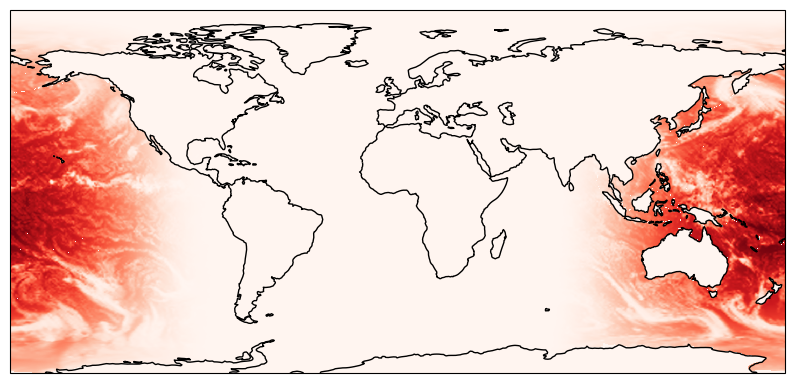

In [9]:
plt.figure(figsize=[10,7])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.pcolormesh(hist_ice["Med_frac_ice_lon"].isel(time=0).squeeze(),
              hist_ice["Med_frac_ice_lat"].isel(time=0).squeeze(),
              hist_ice["iceExp_Faxa_swvdf"].isel(time=0).squeeze(),
              cmap="Reds", transform=ccrs.PlateCarree())
ax.coastlines(color="k")

Check time serie

In [10]:
sample_lon_ERA5 = era5_ds['lon'].isel(lon=60)
sample_lat_ERA5 = era5_ds['lat'].isel(lat=500)

sample_lon_datm = datm_hist['Med_frac_atm_lon'].isel(time=0, Med_frac_atm_nx=60, Med_frac_atm_ny=500)
sample_lat_datm = datm_hist['Med_frac_atm_lat'].isel(time=0, Med_frac_atm_nx=60, Med_frac_atm_ny=500)

print(f"ERA5 lon, lat {sample_lon_ERA5.values:.1f},{sample_lat_ERA5.values:.1f}")
print(f"datm lon, lat {sample_lon_datm.values:.1f},{sample_lat_datm.values:.1f}")

ERA5 lon, lat 15.0,35.0
datm lon, lat 15.0,35.0


In [11]:
jcice = np.abs(hist_ice["Med_frac_ice_lat"].isel(time=0) - 35).argmin(dim="Med_frac_ice_ny").values[0]
icice = np.abs(hist_ice["Med_frac_ice_lon"].isel(time=0, Med_frac_ice_ny=jcice) - 15).argmin(dim="Med_frac_ice_nx").values

print(f"CICE lon, lat = {hist_ice['Med_frac_ice_lon'].isel(time=0, Med_frac_ice_ny=jcice, Med_frac_ice_nx=icice).values:.1f},{hist_ice['Med_frac_ice_lat'].isel(time=0, Med_frac_ice_ny=jcice, Med_frac_ice_nx=icice).values:.1f}")

CICE lon, lat = 15.0,35.0


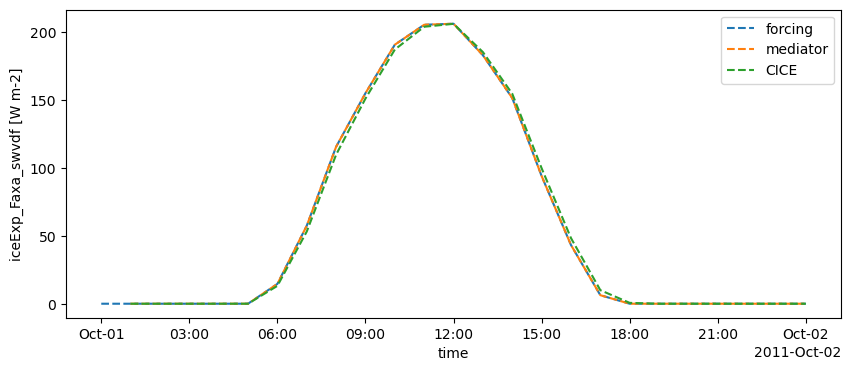

In [12]:
plt.figure(figsize=[10,4])
ax = plt.axes()
era5_ds["vddsf_ave"].isel(lon=60, lat=500).plot(ax=ax, linestyle="--", label="forcing")
datm_hist["atmImp_Faxa_swvdf"].isel(atmImp_nx=60, atmImp_ny=500).plot(ax=ax, linestyle="--", label="mediator")
hist_ice["iceExp_Faxa_swvdf"].isel(iceExp_nx=icice, iceExp_ny=jcice).plot(ax=ax, linestyle="--", label="CICE")
plt.legend()